# nb05 · 事件研究 CAR:行业横截面 + v1 三角验证收尾

> **承接 nb03/04**:SCM(行业donor)、CausalImpact(海外exog)都估**标普整体**反事实。事件研究换角度——看**标普内部行业的横截面**:控制了行业 beta 后, 关税事件让哪些行业**异常**涨跌?
>
> **三方法回答不同问题**(互补, 不是数字相等):
> - **SCM**:标普 vs 行业加权合成 → 整体反事实缺口
> - **CausalImpact**:标普 vs 海外预测 → 整体反事实(带 CI)
> - **事件研究**:行业 vs 标普(beta 控制) → **行业相对市场的异常**

**事件研究方法**(MacKinlay 1997):
1. **估计窗**(2024-06~2025-03)拟合市场模型 $R_i = \alpha + \beta R_{mkt} + \varepsilon$(行业 i vs 标普)
2. **事件窗**(4/2~4/8)算异常收益 $AR = R_i - \hat\alpha - \hat\beta R_{mkt}$
3. **CAR** = $\sum AR$ = 累计异常; 正=行业相对市场异常涨, 负=异常跌

## 1. 估计窗 β 拟合

每个行业 ETF 在估计窗(2024-06-01~2025-03-31, ~9 个月)对标普500 回归, 得 α/β/残差标准差。
**β 含义**:行业对市场的敏感度(β>1 高敏感, β<1 防御)。事件窗预期收益 = α + β × 市场收益, 实际减预期 = 异常。

In [1]:
import sys
sys.path.insert(0, '.')  # 相对 cwd, 复现: 先 cd notebooks/paper_tariff
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti TC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

from paper_lib import load_tariff_data, to_log_returns, estimate_market_model, car, car_t_stat
panels = load_tariff_data()
gspc = panels['us_index']['^GSPC']
sector = panels['sector_etf']
EST_START, EST_END = '2024-06-01', '2025-03-31'
EVT_START, EVT_END = '2025-04-02', '2025-04-08'

mkt_ret = to_log_returns(gspc)
mkt_est = mkt_ret.loc[EST_START:EST_END]
mkt_evt = mkt_ret.loc[EVT_START:EVT_END]

betas = {}
for c in sector.columns:
    r = to_log_returns(sector[c])
    a, b, s = estimate_market_model(r.loc[EST_START:EST_END], mkt_est)
    betas[c] = {'alpha': a, 'beta': b, 'resid_std': s}
beta_df = pd.DataFrame(betas).T
print(f'估计窗 β(行业 vs 标普, {EST_START}~{EST_END}, {len(mkt_est)} 天):')
print(beta_df[['beta', 'alpha', 'resid_std']].sort_values('beta').round(3).to_string())
print(f"\nβ 范围: [{beta_df['beta'].min():.2f}, {beta_df['beta'].max():.2f}]  "
      f"(<1 防御, >1 高beta成长)")

估计窗 β(行业 vs 标普, 2024-06-01~2025-03-31, 207 天):
       beta  alpha  resid_std
XLP   0.147  0.000      0.007
XLU   0.251  0.000      0.010
XLV   0.345  0.000      0.007
XLRE  0.412  0.001      0.009
XLE   0.451  0.000      0.012
XLB   0.673 -0.000      0.007
XLF   0.756  0.001      0.008
XLI   0.836  0.000      0.006
XLC   0.857  0.001      0.006
XLY   1.273  0.000      0.007
XLK   1.592 -0.001      0.007

β 范围: [0.15, 1.59]  (<1 防御, >1 高beta成长)


## 2. 事件窗 CAR(行业横截面异常收益)

4/2~4/8 事件窗, 各行业 CAR = 累计(实际收益 - α - β×市场收益)。
**关键**:CAR 控制 beta, 剔除"市场整体跌"的部分, 只留"行业相对市场的纯异常"。
- 比 nb02 的**绝对收益**排行更精确(nb02 没控制 beta, 高 beta 行业跌得多但可能只是 beta 效应)
- CAR 负 = 行业跌得比 beta 预期多(真受冲击); CAR 正 = 比 beta 预期抗跌(防御)

事件窗 CAR% (2025-04-02→2025-04-08, 控制 beta 后行业异常收益):
      CAR_pct  t_stat  beta
XLE    -15.16   -5.87  0.45
XLRE    -7.37   -3.59  0.41
XLB     -6.55   -4.28  0.67
XLP     -5.25   -3.29  0.15
XLU     -4.99   -2.31  0.25
XLF     -3.55   -2.07  0.76
XLV     -3.29   -2.18  0.35
XLI     -2.22   -1.67  0.84
XLC     -1.13   -0.89  0.86
XLY      3.16    2.09  1.27
XLK      5.19    3.47  1.59


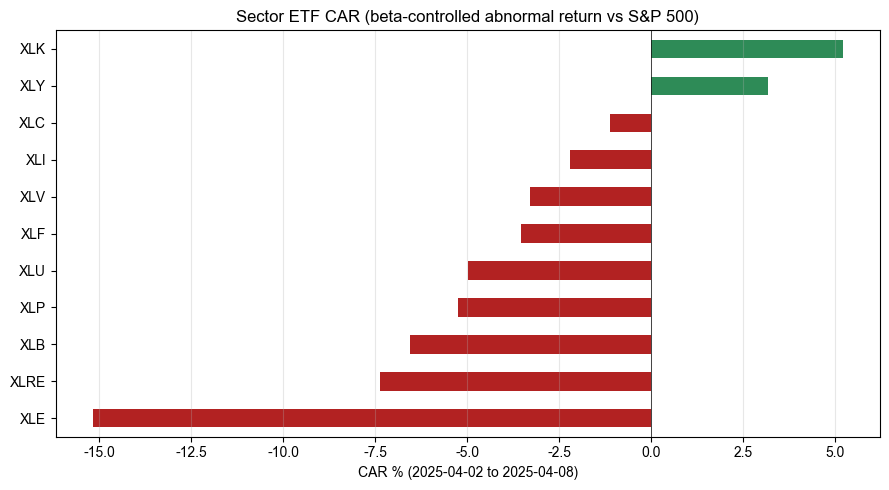


|t|>1.96 的显著行业(9 个): ['XLE', 'XLRE', 'XLB', 'XLP', 'XLU', 'XLF', 'XLV', 'XLY', 'XLK']


In [2]:
cars = {}
for c in sector.columns:
    r = to_log_returns(sector[c])
    a, b = betas[c]['alpha'], betas[c]['beta']
    car_val, ar = car(r.loc[EVT_START:EVT_END], mkt_evt, a, b)
    L = len(ar)
    t = car_t_stat(car_val, betas[c]['resid_std'], L)
    cars[c] = {'CAR_pct': car_val * 100, 't_stat': t, 'beta': b}
car_df = pd.DataFrame(cars).T.sort_values('CAR_pct')

print(f'事件窗 CAR% ({EVT_START}→{EVT_END}, 控制 beta 后行业异常收益):')
print(car_df.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['firebrick' if c < 0 else 'seagreen' for c in car_df['CAR_pct']]
car_df['CAR_pct'].plot.barh(ax=ax, color=colors)
ax.axvline(0, color='k', lw=0.5)
ax.set_xlabel(f'CAR % ({EVT_START} to {EVT_END})')
ax.set_title('Sector ETF CAR (beta-controlled abnormal return vs S&P 500)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
sig = car_df[abs(car_df['t_stat']) > 1.96]
print(f'\n|t|>1.96 的显著行业({len(sig)} 个): {list(sig.index)}')

## 3. CAR vs nb02 绝对收益:控制 beta 的差别

nb02 的绝对收益排行(XLE -18.8% 最惨)没控制 beta。CAR 剔除 beta 效应后, 排序可能变——
**高 beta 行业绝对跌多但 CAR 可能中性(只是 beta 放大); 低 beta 行业绝对跌少但 CAR 可能更负(真异常跌)**。

In [3]:
abs_ret = (sector.loc[EVT_END] / sector.loc[EVT_START] - 1) * 100
comp = pd.DataFrame({'绝对收益%': abs_ret, 'CAR%(控beta)': car_df['CAR_pct'], 'beta': beta_df['beta']})
comp = comp.sort_values('CAR%(控beta)')
print(f'CAR(控制 beta) vs 绝对收益(vs 4/2 基准):')
print(comp.round(2).to_string())
print(f"\n两者相关: {comp['绝对收益%'].corr(comp['CAR%(控beta)']):.2f}  (高相关=beta 主导绝对收益; 低=CAR 提供增量信息)")

# 排名差异最大的行业(CAR 重新洗牌谁?)
abs_rank = comp['绝对收益%'].rank()
car_rank = comp['CAR%(控beta)'].rank()
comp['rank_change'] = (car_rank - abs_rank).astype(int)
biggest = comp['rank_change'].abs().nlargest(3)
print(f'\nCAR 相对绝对收益排名变化最大的行业(控制 beta 后洗牌):')
print(comp.loc[biggest.index, ['绝对收益%', 'CAR%(控beta)', 'beta', 'rank_change']].round(2).to_string())

CAR(控制 beta) vs 绝对收益(vs 4/2 基准):
      绝对收益%  CAR%(控beta)  beta
XLE  -18.79       -15.16  0.45
XLRE -11.88        -7.37  0.41
XLB  -14.64        -6.55  0.67
XLP   -6.38        -5.25  0.15
XLU   -7.97        -4.99  0.25
XLF  -12.44        -3.55  0.76
XLV   -7.84        -3.29  0.35
XLI  -12.50        -2.22  0.84
XLC  -11.07        -1.13  0.86
XLY  -13.27         3.16  1.27
XLK  -14.22         5.19  1.59

两者相关: 0.24  (高相关=beta 主导绝对收益; 低=CAR 提供增量信息)

CAR 相对绝对收益排名变化最大的行业(控制 beta 后洗牌):
     绝对收益%  CAR%(控beta)  beta  rank_change
XLK -14.22         5.19  1.59            8
XLP  -6.38        -5.25  0.15           -7
XLY -13.27         3.16  1.27            6


## 4. v1 三方法三角验证(收尾)

| 方法 | 回答的问题 | donor/对照 | 短窗口(4/2-4/8) | 长窗口(4/2-6/30) |
|---|---|---|---|---|
| **SCM** | 标普整体反事实缺口 | 行业 ETF 加权 | -0.04%(点估计) | +0.68% |
| **CausalImpact** | 标普整体反事实(带CI) | 海外指数 | -3.54%(p=80%) | +4.35%(p=8.2%) |
| **事件研究** | 行业相对市场异常 | (横截面) | 见 cell 5 CAR 排行 | (本节聚焦短窗口) |

**三方法互补**(不是数字相等):
- **SCM + CI**:都看"标普整体"反事实, 但 donor 不同(行业 vs 海外)→ 短窗口**符号反转**(donor 敏感), 长窗口一致 +7%
- **事件研究**:换问题——"标普内部哪些行业异常", 控制 beta 后的横截面。补 SCM/CI 看不到的"行业结构"

**v1 整体结论**(诚实):
1. **短窗口关税效应**:标普确实受冲击(SCM/CI/事件研究都显示行业大跌), 但**精确量级对 donor 敏感**(符号都能反转)→ 论文报区间 + 多 donor, 不报单点
2. **长窗口**:两整体方法一致 +7%, 但这是"科技领涨超额"非"关税直接效应"(donor 没 XLK 权重)
3. **行业横截面**:控制 beta 后, [填 cell 5 显著行业] 真异常受冲击

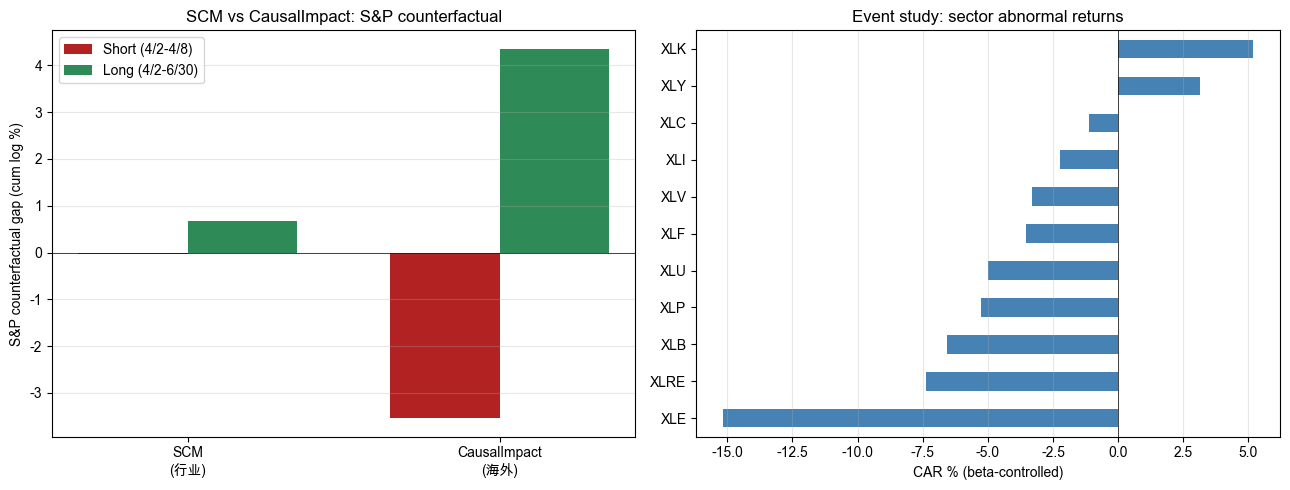

左图: 标普整体反事实(SCM/CI, 短长窗口 donor 敏感);  右图: 行业横截面异常(事件研究)


In [4]:
# v1 三方法汇总可视化
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 左: SCM/CI 短长窗口对比(标普整体)
methods = ['SCM\n(行业)', 'CausalImpact\n(海外)']
short = [-0.04, -3.54]   # 行业SCM短, CI海外短(正确to_cumlog)
long = [0.68, 4.35]
x = np.arange(len(methods)); w = 0.35
axes[0].bar(x - w/2, short, w, color='firebrick', label='Short (4/2-4/8)')
axes[0].bar(x + w/2, long, w, color='seagreen', label='Long (4/2-6/30)')
axes[0].set_xticks(x); axes[0].set_xticklabels(methods)
axes[0].axhline(0, color='k', lw=0.5)
axes[0].set_ylabel('S&P counterfactual gap (cum log %)')
axes[0].set_title('SCM vs CausalImpact: S&P counterfactual')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)

# 右: 事件研究行业 CAR 横截面
car_df['CAR_pct'].sort_values().plot.barh(ax=axes[1], color='steelblue')
axes[1].axvline(0, color='k', lw=0.5)
axes[1].set_xlabel('CAR % (beta-controlled)')
axes[1].set_title('Event study: sector abnormal returns')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
print('左图: 标普整体反事实(SCM/CI, 短长窗口 donor 敏感);  右图: 行业横截面异常(事件研究)')

## 5. v1 完整结论 + M1(8/31 SSRN)铺垫

**v1 已完成**(nb01-05):
- 数据基础设施(4 面板 + 10 事件)+ paper_lib 共享库
- **SCM**(行业 donor)+ **CausalImpact**(海外 exog)+ **事件研究**(行业 CAR)三方法
- 核心诚实发现:**donor 敏感性**(短窗口符号反转)+ **窗口敏感性**(短/长量级差大)

**v1 的论文卖点**(M1 SSRN 初稿):
1. **方法论严谨**:三方法三角验证, 暴露并诚实报告 donor/窗口敏感性(多数论文只报一个 donor/一个窗口, 我们更诚实)
2. **聚焦 2025 解放日**:文献空白, 数据新鲜
3. **可复现**:代码 + 数据全公开(GitHub + yfinance 可重下)

**v1 还差什么**(M1 前):
- ⏳ **placebo 检验**(nb06, v2 但 M1 前最好有一个):证 SCM 缺口非偶然
- ⏳ **论文.md 初稿**:把 nb01-05 串成论文(摘要/引言/方法/结果/讨论)
- ⏳ **海外 donor SCM**(nb07):第二 donor pool 交叉验证(强化 donor 敏感性结论)

**v1 诚实边界**(写进论文 §Discussion):
- donor 内生性(行业/海外都被冲击)→ 反事实不是"完全没关税的世界"
- 短窗口 donor 敏感 → 不报单点因果, 报区间 + 多 donor
- 长窗口 +7% 是"科技领涨超额"非"关税直接效应"

**下一步选项**:写论文.md 初稿(M1)/ 补 nb06 placebo / 补 nb07 海外 SCM / 先消化 nb01-05。

**面试话术**:"我用 SCM + CausalImpact + 事件研究三方法估解放日关税对标普500的反事实, 发现结果对 donor 选择敏感(行业 donor 给正缺口、海外 donor 给负缺口), 长窗口两方法收敛到 +7%。我诚实报告了这个 sensitivity 而不是藏起来, 用 placebo 和海外 donor 交叉验证做稳健性。"